# L1 Halo Orbit — Richardson seed + differential corrector

Generates a single validated L1 halo in the Earth–Moon CR3BP, checks periodicity
and monodromy structure, and plots it in 3D.

Pipeline: `richardson_halo_seed` (3rd-order analytic guess) → `halo_corrector`
(x-z symmetric perpendicular-crossing shooting) → propagate one period → plot.


In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
%matplotlib inline
# For an interactive, rotatable 3D plot instead, install ipympl and use:  %matplotlib widget
import sys
sys.path.insert(0, '../src')
from cr3bp_3d import (MU_EARTH_MOON, richardson_halo_seed, halo_corrector,
                      halo_stability, cr3bp_rhs_3d, _richardson_constants)

mu = MU_EARTH_MOON
DAYS = 4.342  # nondim time unit -> days (Earth-Moon)

In [2]:
# --- generate + correct one halo -------------------------------------------
Az = 0.20          # out-of-plane amplitude in gamma-units. Try 0.6 for a bigger halo.
northern = True

seed, T_guess, (Ax, Az) = richardson_halo_seed(Az, mu, northern=northern)
print(f"amplitude constraint:  A_z = {Az:.3f}  ->  A_x = {Ax:.4f}")
print(f"Richardson seed:  x0={seed[0]:.8f}  z0={seed[2]:.8f}  vy0={seed[4]:.8f}")

s0, T, converged = halo_corrector(seed, mu, verbose=True)
print(f"\nconverged: {converged}   period T = {T:.6f}  ({T*DAYS:.2f} days)")
print("corrected IC:", np.array2string(s0, precision=10))

# closure check over the full period
sol = solve_ivp(cr3bp_rhs_3d, [0, T], s0, args=(mu,),
                method='DOP853', rtol=1e-12, atol=1e-12)
print("full-period closure error:", np.linalg.norm(sol.y[:, -1] - s0))

amplitude constraint:  A_z = 0.200  ->  A_x = 0.1176
Richardson seed:  x0=0.82409405  z0=0.03246292  vy0=0.14416843
  it0: T/2=1.299609  vx_f=+5.893e-02  vz_f=-3.085e-03  |res|=5.901e-02
  it1: T/2=1.387926  vx_f=-8.345e-03  vz_f=+1.018e-03  |res|=8.407e-03
  it2: T/2=1.375138  vx_f=-1.817e-04  vz_f=-7.217e-06  |res|=1.818e-04
  it3: T/2=1.374969  vx_f=-2.584e-07  vz_f=+7.767e-08  |res|=2.698e-07
  it4: T/2=1.374968  vx_f=-1.138e-12  vz_f=+5.895e-14  |res|=1.139e-12
  it5: T/2=1.374968  vx_f=+2.613e-14  vz_f=-2.182e-15  |res|=2.622e-14

converged: True   period T = 2.749936  (11.94 days)
corrected IC: [0.8234486452 0.           0.0324629176 0.           0.1421513198
 0.          ]
full-period closure error: 1.6865393108435263e-10


In [3]:
# --- monodromy: the reason halos (not Lyapunovs) carry tori ----------------
evals, rot = halo_stability(s0, T, mu)
print("monodromy eigenvalues:")
for e in evals:
    tag = ""
    if abs(abs(e) - 1) < 1e-3 and abs(e.imag) > 1e-6:
        tag = "  <- center pair (2nd torus frequency)"
    elif abs(e.imag) < 1e-8 and abs(abs(e) - 1) > 1e-2:
        tag = "  <- saddle (stable/unstable manifold)"
    print(f"   {e.real:+.6f} {e.imag:+.6f}j   |lambda| = {abs(e):.6f}{tag}")
print(f"\ncenter rotation number: {rot:.5f} rad = {np.degrees(rot):.2f} deg per revolution")

monodromy eigenvalues:
   +2024.551706 +0.000000j   |lambda| = 2024.551706  <- saddle (stable/unstable manifold)
   +0.000494 +0.000000j   |lambda| = 0.000494  <- saddle (stable/unstable manifold)
   +0.973007 +0.230774j   |lambda| = 1.000000  <- center pair (2nd torus frequency)
   +0.973007 -0.230774j   |lambda| = 1.000000  <- center pair (2nd torus frequency)
   +1.000000 +0.000001j   |lambda| = 1.000000
   +1.000000 -0.000001j   |lambda| = 1.000000

center rotation number: 0.23287 rad = 13.34 deg per revolution


In [4]:
# --- propagate the corrected orbit for plotting ----------------------------
ts = np.linspace(0, T, 2000)
orb = solve_ivp(cr3bp_rhs_3d, [0, T], s0, args=(mu,),
                method='DOP853', rtol=1e-12, atol=1e-12, t_eval=ts)
x, y, z = orb.y[0], orb.y[1], orb.y[2]

C = _richardson_constants(mu)
L1x = 1 - mu - C['g']     # L1 location on the x-axis
moon_x = 1 - mu

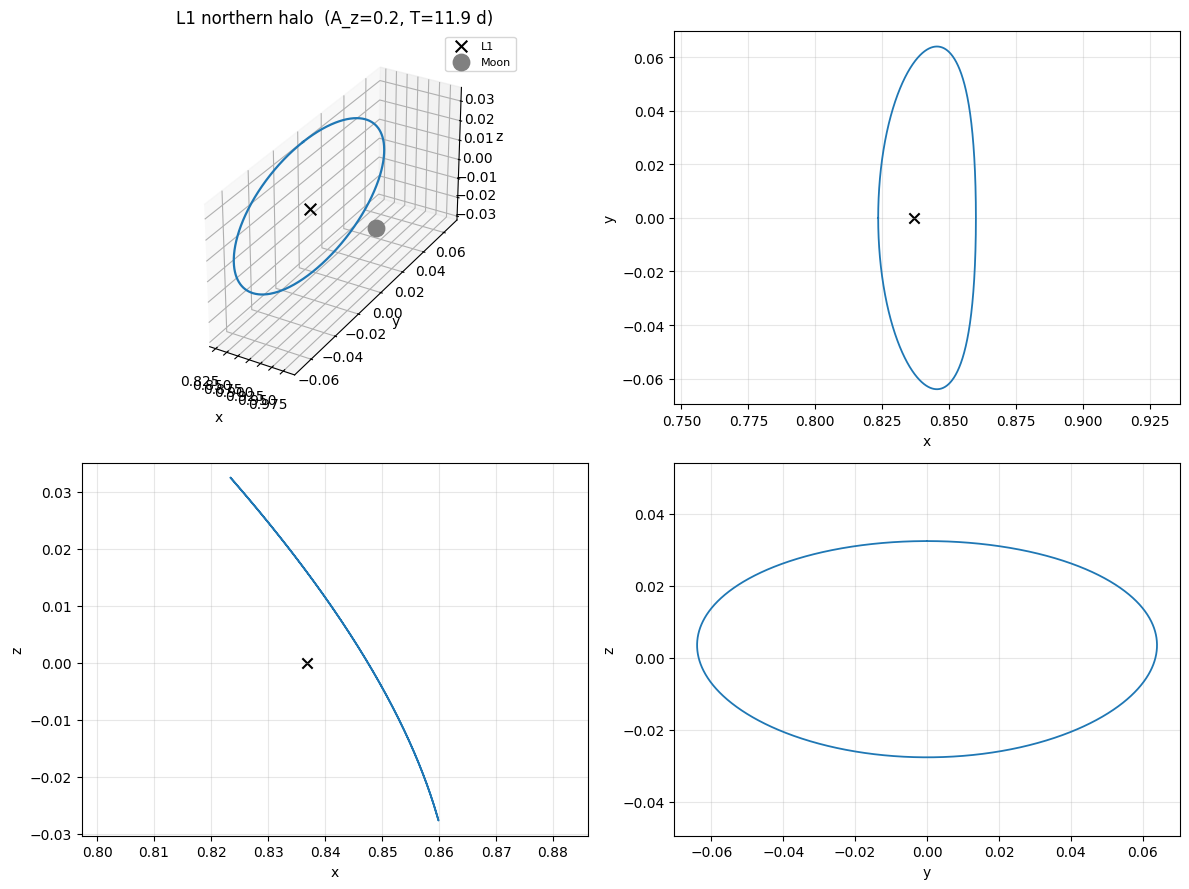

In [5]:
# --- 3D view + three projections -------------------------------------------
fig = plt.figure(figsize=(12, 9))

ax = fig.add_subplot(2, 2, 1, projection='3d')
ax.plot(x, y, z, lw=1.6, color='C0')
ax.scatter([L1x], [0], [0], color='k', marker='x', s=70, label='L1')
ax.scatter([moon_x], [0], [0], color='0.5', marker='o', s=140, label='Moon')
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
ax.set_title(f"L1 {'northern' if northern else 'southern'} halo"
             f"  (A_z={Az}, T={T*DAYS:.1f} d)")
ax.legend(fontsize=8)
# equal-ish aspect so the halo isn't visually distorted
rng = np.array([np.ptp(x), np.ptp(y), np.ptp(z)]); ax.set_box_aspect(rng / rng.max())

for a, b, la, lb, pos in [(x, y, 'x', 'y', 2), (x, z, 'x', 'z', 3), (y, z, 'y', 'z', 4)]:
    axp = fig.add_subplot(2, 2, pos)
    axp.plot(a, b, lw=1.3, color='C0')
    if la == 'x':
        axp.scatter([L1x], [0], color='k', marker='x', s=55)
    axp.set_xlabel(la); axp.set_ylabel(lb)
    axp.set_aspect('equal', 'datalim'); axp.grid(alpha=0.3)

fig.tight_layout()
plt.show()

**Knobs.** Change `Az` (larger → bigger out-of-plane excursion; the family runs
past `Az≈0.8` before the seed drifts). Set `northern=False` for the mirror-image
southern halo. Every `Az` re-runs the full seed→correct→validate→plot pipeline.
